# 04 — M3 12-month forecasts

SARIMA vs Holt-Winters, holdout quality, and the 2021/2022 sensitivity. The full refit takes minutes; this notebook reads the outputs.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BACKEND = Path.cwd()
if not (BACKEND / "src").exists():
    BACKEND = BACKEND.parent
sys.path.insert(0, str(BACKEND / "src"))
PROCESSED = BACKEND / "data" / "processed"
REPORTS = BACKEND / "reports"


In [2]:
summary = pd.read_csv(PROCESSED / "model_m3_summary.csv")
diag = pd.read_csv(PROCESSED / "model_m3_diagnostics.csv")
print("cities:", len(summary))
print(summary["winner"].value_counts(dropna=False).to_dict())
print(summary["forecast_quality"].value_counts(dropna=False).to_dict())
display(summary.head(10).round(3))

cities: 51
{'SARIMA': 28, 'Holt-Winters': 23}
{'ok': 51}


,city,winner,order,seasonal_order,d,aic,sarima_rmse,hw_rmse,sarima_mae,hw_mae,...,forecast_growth,sarima_forecast_12m,sarima_forecast_growth,hw_forecast_12m,hw_forecast_growth,sarima_status,hw_status,holdout_rmse_rel,forecast_quality,skip_reason
0,Jaipur,Holt-Winters,"(1, 0, 1)","(1, 1, 0, 12)",0,18.2,1339.6,1275.9,1063.5,1031.4,...,1.101,47026.0,0.544,63996.0,1.101,ok,ok,0.051,ok,NaN
1,Rajkot,SARIMA,"(2, 1, 2)","(1, 1, 1, 12)",1,51.3,362.4,396.1,326.3,343.8,...,0.901,15780.0,0.901,11875.0,0.431,ok,ok,0.052,ok,NaN
2,Bhubaneswar,SARIMA,"(0, 1, 2)","(1, 1, 0, 12)",1,-2.0,1458.2,1538.7,1212.0,1320.6,...,0.680,60525.0,0.680,69891.0,0.940,ok,ok,0.049,ok,NaN
3,Guwahati,Holt-Winters,"(2, 1, 1)","(1, 1, 0, 12)",1,30.2,642.0,522.5,523.9,433.4,...,0.668,22943.0,0.578,24258.0,0.668,ok,ok,0.044,ok,NaN
4,Pune,Holt-Winters,"(1, 0, 1)","(1, 1, 0, 12)",0,3.8,2432.4,2424.8,1929.0,1991.8,...,0.582,77143.0,0.139,107179.0,0.582,ok,ok,0.044,ok,NaN
5,Madurai,SARIMA,"(0, 1, 1)","(1, 1, 0, 12)",1,-4.6,254.5,266.2,226.9,236.0,...,0.574,8585.0,0.574,11165.0,1.047,ok,ok,0.054,ok,NaN
6,Gurugram,SARIMA,"(0, 0, 2)","(1, 1, 1, 12)",0,40.6,225.1,257.0,144.8,180.5,...,0.561,5055.0,0.561,9853.0,2.043,ok,ok,0.086,ok,NaN
7,Srinagar,SARIMA,"(0, 1, 1)","(0, 1, 1, 12)",1,10.1,118.5,126.2,103.9,111.3,...,0.546,4780.0,0.546,3813.0,0.233,ok,ok,0.046,ok,NaN
8,Nashik,SARIMA,"(2, 1, 1)","(1, 1, 0, 12)",1,28.7,904.8,918.6,773.7,817.5,...,0.534,45007.0,0.534,40182.0,0.369,ok,ok,0.038,ok,NaN
9,Noida,SARIMA,"(0, 1, 2)","(0, 1, 1, 12)",1,3.0,425.4,506.3,343.7,413.3,...,0.519,33496.0,0.519,30971.0,0.405,ok,ok,0.025,ok,NaN


In [3]:
print("median holdout RMSE / last-12m:", round(float(summary["holdout_rmse_rel"].median()), 3))
print("max |SARIMA forecast|:", float(summary["sarima_forecast_12m"].abs().max()))
print("non-finite forecasts:", int((~np.isfinite(summary["forecast_12m"].dropna())).sum()))

median holdout RMSE / last-12m: 0.032
max |SARIMA forecast|: 172990.0
non-finite forecasts: 0


## Forecast paths for the strongest cities

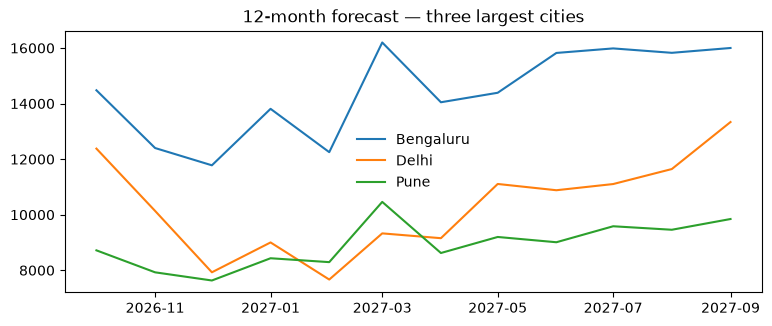

In [4]:
forecasts = pd.read_csv(PROCESSED / "model_m3_forecasts.csv", parse_dates=["date"])
top = summary.nlargest(3, "last_12m")["city"]
fig, ax = plt.subplots(figsize=(9, 3.4))
for city in top:
    sub = forecasts[forecasts["city"] == city]
    ax.plot(sub["date"], sub["forecast"], label=city)
ax.set_title("12-month forecast — three largest cities")
ax.legend(frameon=False)
plt.show()

## 2021 vs 2022-only sensitivity

In [5]:
path = PROCESSED / "model_m3_2022only.csv"
if path.exists():
    sens = pd.read_csv(path)
    display(sens.reindex(sens["growth_delta"].abs().sort_values(ascending=False).index).head(8))
else:
    print("run scripts/diagnose_seam.py --with-m3")

,city,forecast_growth,forecast_quality,winner_2022only,growth_2022only,quality_2022only,rmse_rel_2022only,growth_delta
6,Bhopal,0.2561,ok,Holt-Winters,0.6626,ok,0.0292,0.4065
16,Guwahati,0.6680,ok,Holt-Winters,0.4053,ok,0.0445,-0.2627
41,Rajkot,0.9013,ok,Holt-Winters,0.6404,ok,0.0565,-0.2609
39,Pune,0.5819,ok,Holt-Winters,0.3409,ok,0.0448,-0.2410
0,Agra,0.2332,ok,SARIMA,0.4358,ok,0.0181,0.2026
20,Jabalpur,0.3901,ok,SARIMA,0.5794,ok,0.0326,0.1893
38,Patna,0.4269,ok,SARIMA,0.5917,ok,0.0320,0.1648
26,Kolkata,0.3402,ok,SARIMA,0.1801,ok,0.0279,-0.1601
